In [138]:
"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #02 - Successive Corrections

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using successive corrections.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"

In [139]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles
import pandas as pd
import os
os.environ["PROJ_IGNORE_CELESTIAL_BODY"]="YES"

In [140]:
### Read in observations ###
df = pd.read_csv('RAOBs_201903131200.txt',sep=',',header=None)
latitude = df[1]
longitude = df[2]
df['h500'] = df[3]

In [141]:
### Set up analysis map with a 21x27 rectangular grid of points ###

nx,ny=(21, 27) #set up grid
x0=25 #initial x and y
y0=-15.5
rho=6371000 # earth's radius
m=1/15000000 #scale factor
phi0=60
lambda0=-100

yv=y0+(np.arange(ny))*1.27 # x and y coordinates of grid points, spaced 1.27cm apart
xv=x0+(np.arange(nx))*1.27
xcm, ycm=np.meshgrid(xv,yv, indexing='ij') #create grid


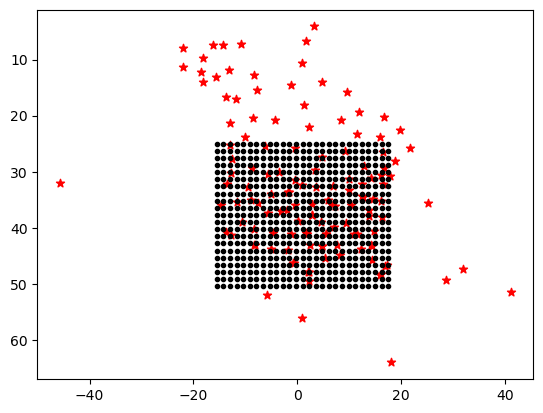

In [142]:
### convert obs lat/long to x,y ###
x=xcm/100/m
y=ycm/100/m
r=np.sqrt(x**2+y**2)

psi0=90-phi0 #psi in degrees

phi=np.pi/2-2*np.arctan(r/(rho*(1+np.cos(np.radians(psi0)))))
lam=np.arctan2(y,x) 
gridlat=np.degrees(phi) #grid points lat
gridlon=(lambda0+np.degrees(lam)+180)%360-180 #grid points lon

phi=np.radians(latitude)
lam=np.radians(longitude-lambda0)

sigma=(1+np.sin(np.radians(phi0)))/(1+np.sin(phi)) #
R=m*sigma*rho*np.cos(phi)
df['X']=100*R*np.cos(lam)
df['Y']=100*R*np.sin(lam)

plt.plot(ycm,xcm,marker='.',color='k',linestyle='none')
plt.gca().invert_yaxis()

#print (lon)
#print (ycm) #sanity check
plt.scatter(df['Y'],df['X'],marker='*',color='r')
plt.show()


In [143]:
#dik (distance between ith analysis point and kth obs point)
dik=[]
df['i']=(((df['X']-x0)/1.27)).astype(int) #set up indices
df['j']=((df['Y']-y0)/1.27).astype(int)

for i in range(21): #iterate over i
        for j in range(27): #over j, ensures running analysis for each grid point
            xi=xcm[i,j] # x coordinates for all grid points
            yi=ycm[i,j] # y coordinates for all grid points
            dfpx=df['X']-xi # x distance between grid point and obs
            dfpy=df['Y']-yi # y distance between grid point and obs
            d=np.sqrt(dfpx**2+dfpy**2) #shortest distance between point and obs
            dik.append(d)
print (len(dik)) #sanity check, len is 567 (which is 21*27) and each has 135, so distance from every grid point to every obs point)

567


In [144]:
#get dmin (avg distance between nearest rawinsondes in dataset)
dminl = []
X=100*R*np.cos(lam)
Y=100*R*np.sin(lam)
for i in range (0,134):
    disraw=[] #disraw=distance rawinsonde
    for j in range (0,134): #iterate over every grid point to find nearest rawinsonde
        if i==j:
            continue
        dX=X[i]-X[j] #x distance between rawinsondes
        dY=Y[i]-Y[j] #y distance between rawinsondes
        draw=[np.sqrt(dY**2+dX**2)] #distance between rawinsondes
        disraw.append(draw) #add to list
    dmin=np.min(disraw) #find min distance on list for given iteration
    dminl.append(dmin) #add min distance to list
mind=(np.mean(dminl)) #average shortest distance between rawinsondes

#get ROIs
R=mind*np.array([4,2.5,1.5])
#print (R[1])
#R=[10.219,6.387,3.382]

In [145]:
##this cressman works for 1st pass, awkward to adjust for 2nd and 3rd :(
# #cressman weight
# #dik=[]
# height=h500
# i=(((xcm-x0)/1.27)).astype(int) #set up indices
# j=((ycm-y0)/1.27).astype(int)
# grid=np.meshgrid(xv,yv, indexing='ij')

# #cressgrid=np.full((21,27), 0)

# def cressman (R,grid,height=h500,alt=np.nan):
#     cressgrid=np.full((21,27),np.nan)
#     for i in range(21): #iterate over i
#         for j in range(27): #over j, ensures running analysis for each grid point
            
#             xi=xcm[i,j] # x coordinates for all grid points
#             yi=ycm[i,j] # y coordinates for all grid points
#             dfpx=X-xi # x distance between grid point and obs
#             dfpy=Y-yi # y distance between grid point and obs
#             d=np.sqrt(dfpx**2+dfpy**2) #shortest distance between point and obs
#             mask=d<=R #check if within ROI
#             if np.any(mask):
#                 height_mask=height[mask]
#                 w=(R**2-d[mask]**2)/(R**2+d[mask]**2) #cressman weight function
#                 try:
#                     wavg=np.sum(w*height_mask)/np.sum(w) #1st pass analysis values
#                     cressgrid[i,j]=wavg
#                 except:
#                     cressgrid[i,j]=alt
#     return cressgrid

In [146]:
#cressman functions
def cressw(R,d):
    w=np.where(d<=R,(R**2-d**2)/(R**2+d**2),0.0)
    return w #just finds cressman weights

def cressman(x,y,xd,yd,vals,R):
    d=np.sqrt((xd-x)**2+(yd-y)**2)
    w=cressw(R,d)
    wsum=w.sum()
    if wsum==0:
        return np.nan
    return (w*vals).sum()/wsum

In [147]:
xobsloc=df['X'].values #x coordinate of obs
yobsloc=df['Y'].values #y coordinate of obs
obsheight=df['h500'].values #height of obs
Xij,Yij=xcm,ycm #grid points

In [148]:
A1=np.full((nx,ny),np.nan) #1st pass, only cressman. (generating bg)
for i in range(nx):
    for j in range(ny): #iterate over all points in grid
        A1[i,j]=cressman(Xij[i,j],Yij[i,j],xobsloc,yobsloc,obsheight,R[0])
#print (A1) sanity check

In [149]:
#bilinear interp function, for estimating height at observation locations outside grid
def bi_interp(analysis,ifr,jfr,nx,ny):
    if np.isnan(ifr) or np.isnan(jfr):
        return np.nan
    fx=int(np.floor(ifr)) #floor x
    cx=int(np.ceil(ifr)) #ceiling x
    fy=int(np.floor(jfr)) #floor y
    cy=int(np.ceil(jfr)) #ceiling y
    if fx<0 or fy<0 or cx>nx-1 or cy>ny-1:
        return np.nan #assign NaN to points outside grid
    di=ifr-fx
    dj=jfr-fy
    #bilinear formula
    val_at_obs=(analysis[fx,fy]*(1-di)*(1-dj)+analysis[cx,fy]*di*(1-dj)+analysis[fx, cy]*(1-di)*dj+analysis[cx,cy]*di*dj)
    return val_at_obs

In [150]:
A1obsestimate=np.full(135,np.nan) #estimate values at observation stations pass 1 w bilinear
for k in range(135):
    v=bi_interp(A1,df['i'].values[k],df['j'].values[k],nx,ny) #apply bilinear
    if np.isnan(v):
        v=cressman(xobsloc[k],yobsloc[k],Xij.ravel(),Yij.ravel(),A1.ravel(),R[0]) # .ravel flattens to 1D
    A1obsestimate[k]=v

In [151]:
A2=np.full((nx,ny),np.nan)
include=np.isfinite(A1obsestimate) #ignore obs locations flagged as NaN
for i in range (nx):
    for j in range (ny):
        if np.isnan(A1[i,j]):
            continue
        d=np.sqrt((xobsloc[include]-Xij[i,j])**2+(yobsloc[include]-Yij[i,j])**2) #distance formula for obs
        w=cressw(R[1],d) #apply cressman
        wsum=w.sum()
        if wsum==0:
            A2[i,j]=A1[i,j] #keep same value if no obs in ROI
            continue
        cor=(w*(obsheight[include]-A1obsestimate[include])).sum()/wsum #correction
        A2[i,j]=A1[i,j]+cor
#print (A1obs)

In [152]:
A2obsestimate=np.full(135,np.nan) #estimate values at obs stations pass 2
for k in range(135):
    v=bi_interp(A2,df['i'].values[k],df['j'].values[k],nx,ny)
    if np.isnan(v):
        v=cressman(xobsloc[k],yobsloc[k],Xij.ravel(),Yij.ravel(),A2.ravel(),R[1])
    A2obsestimate[k]=v

In [153]:
A3=np.full((nx,ny),np.nan) #similar to A2
include=np.isfinite(A2obsestimate)
for i in range (nx):
    for j in range (ny):
        if np.isnan(A2[i,j]):
            continue
        d=np.sqrt((xobsloc[include]-Xij[i,j])**2+(yobsloc[include]-Yij[i,j])**2)
        w=cressw(R[2],d)
        wsum=w.sum()
        if wsum==0:
            A3[i,j]=A2[i,j]
            continue
        cor=(w*(obsheight[include]-A2obsestimate[include])).sum()/wsum
        A3[i,j]=A2[i,j]+cor

/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


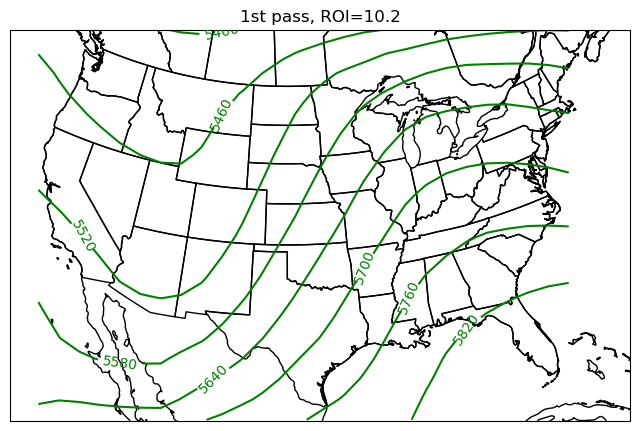

In [154]:
#plot 1st pass analysis
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)

levels=np.arange(0,8000,60)
cs1 = ax1.contour(gridlon,gridlat,A1,colors='g',levels=np.arange(0,8000,60), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("1st pass, ROI=10.2")

plt.show()

/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


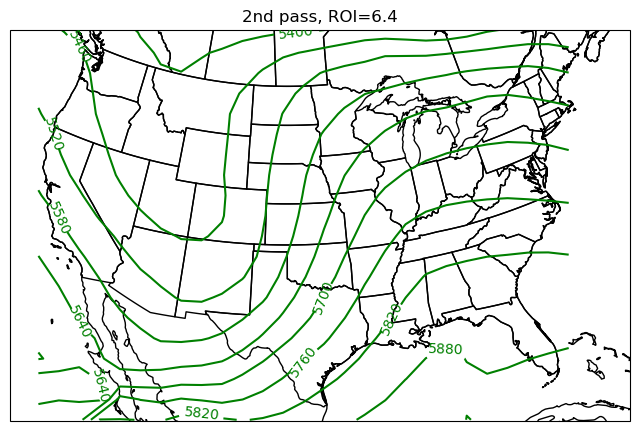

In [155]:
#plot 2nd pass analysis
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)

levels=np.arange(0,8000,60)
cs1 = ax1.contour(gridlon,gridlat,A2,colors='g',levels=np.arange(0,8000,60), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("2nd pass, ROI=6.4")

plt.show()

/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


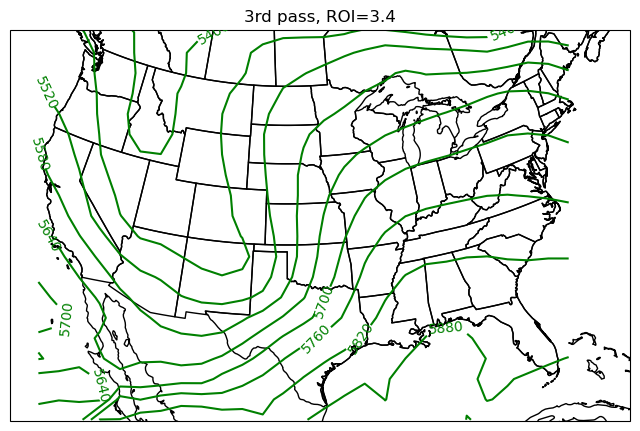

In [156]:
#plot 3rd pass analysis
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)

levels=np.arange(0,8000,60)
cs1 = ax1.contour(gridlon,gridlat,A3,colors='g',levels=np.arange(0,8000,60), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("3rd pass, ROI=3.4")

plt.show()

/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


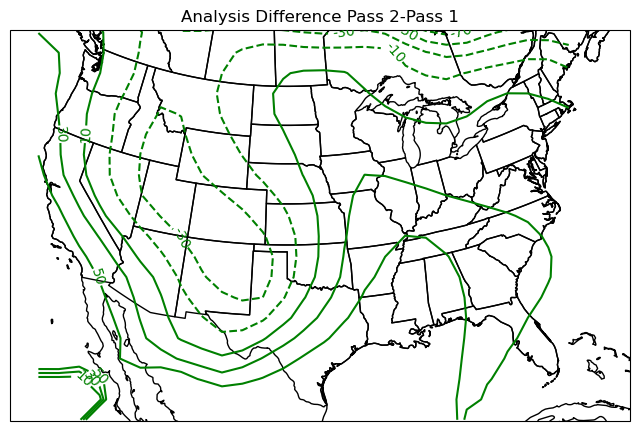

/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


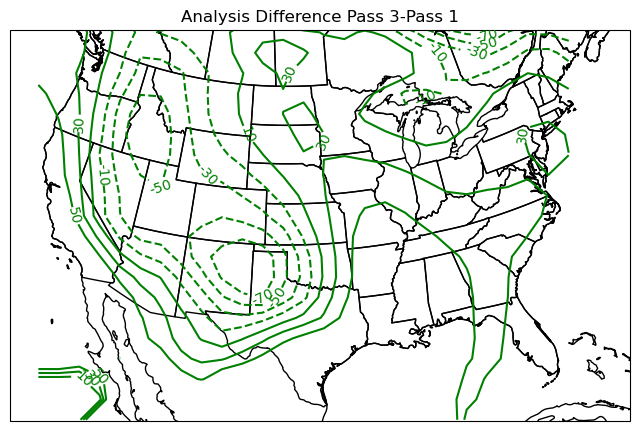

/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


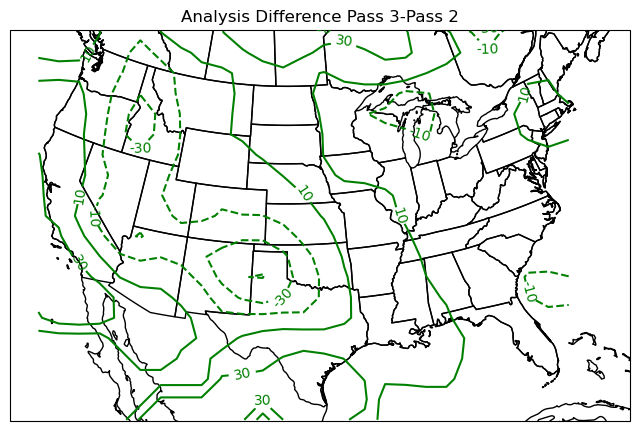

In [157]:
#analysis differences
A2A1diff=A2-A1
A3A1diff=A3-A1
A3A2diff=A3-A2

#plot analysis differences
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
# plot number of observations (MAY NEED TO CHANGE VARIABLE NAMES/INDICES) #
#levels=np.arange(-80,10,80)
cs1 = ax1.contour(gridlon,gridlat,A2A1diff,colors='g',levels=np.arange(-70,70,20), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("Analysis Difference Pass 2-Pass 1")

plt.show()


globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
# plot number of observations (MAY NEED TO CHANGE VARIABLE NAMES/INDICES) #
levels=np.arange(0,800,10)
cs1 = ax1.contour(gridlon,gridlat,A3A1diff,colors='g',levels=np.arange(-70,70,20), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("Analysis Difference Pass 3-Pass 1")

plt.show()


globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
# plot number of observations (MAY NEED TO CHANGE VARIABLE NAMES/INDICES) #
levels=np.arange(0,800,10)
cs1 = ax1.contour(gridlon,gridlat,A3A2diff,colors='g',levels=np.arange(-70,70,20), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("Analysis Difference Pass 3-Pass 2")

plt.show()

In [ ]:
### In a separate text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.
    All analyses show a trough in the western US and a ridge to the east.

2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?
    Pass 1 is the smoothest, followed by pass 2 and then 3. All have a trough and ridge present, but differ
    in how dramatic the features appear. Pass 3 is able to resolve finer details than the other two passes.
    Pass 1 is smoother than the others. This is likely because pass 1 had the largest ROI and so took more 
    observation points into consideration when generating the background grid.

3 - What happens as you increase the number of successive correction passes?  Is this 
    desirable?  Why or why not?
    As you increase the number of successive correction passes, the analyses get less smooth. This is 
    desirable to a degree because the trough and ridge are more clearly resolved as ROIs are shrinking, 
    bringing the analyses closer to truth (observations). If ROIs are too small, the contours may become
    so jagged/try to resolve such small details as to make the analysis useless.

'''